In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns

In [2]:
# Upload the file first in Colab (click folder icon → Upload)
df = pd.read_csv("healthcare-dataset-stroke-data.csv")

# Show first 5 rows
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [3]:
print("Dataset Shape:", df.shape)
print("\nMissing Values:")
print(df.isnull().sum())
print("\nData Types:")
print(df.dtypes)
print("\nStroke Class Distribution:")
print(df['stroke'].value_counts())

Dataset Shape: (5110, 12)

Missing Values:
id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

Data Types:
id                     int64
gender                object
age                  float64
hypertension           int64
heart_disease          int64
ever_married          object
work_type             object
Residence_type        object
avg_glucose_level    float64
bmi                  float64
smoking_status        object
stroke                 int64
dtype: object

Stroke Class Distribution:
stroke
0    4861
1     249
Name: count, dtype: int64


In [4]:
# Replace "N/A" in BMI with actual missing value
df['bmi'] = df['bmi'].replace('N/A', np.nan)
df['bmi'] = pd.to_numeric(df['bmi'])

# Fill missing BMI with median
df['bmi'].fillna(df['bmi'].median(), inplace=True)

# Drop the 'id' column (not useful)
df = df.drop('id', axis=1)

# Encode categorical columns
categorical_cols = ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']

le = LabelEncoder()
for col in categorical_cols:
    df[col] = le.fit_transform(df[col])

# Check the cleaned data
df.head()

/tmp/ipykernel_577/143695611.py:6: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['bmi'].fillna(df['bmi'].median(), inplace=True)


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,1,67.0,0,1,1,2,1,228.69,36.6,1,1
1,0,61.0,0,0,1,3,0,202.21,28.1,2,1
2,1,80.0,0,1,1,2,0,105.92,32.5,2,1
3,0,49.0,0,0,1,2,1,171.23,34.4,3,1
4,0,79.0,1,0,1,3,0,174.12,24.0,2,1


In [5]:
# Features and Target
X = df.drop('stroke', axis=1)
y = df['stroke']

# Split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training set size:", X_train.shape)
print("Testing set size:", X_test.shape)

Training set size: (4088, 10)
Testing set size: (1022, 10)


In [6]:
# Create the model
model = LogisticRegression(max_iter=1000, random_state=42)

# Train the model
model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [7]:
# Predict on test set
y_pred = model.predict(X_test)

# Accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy:.4f}")

# Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Model Accuracy: 0.9393

Classification Report:
              precision    recall  f1-score   support

           0       0.94      1.00      0.97       960
           1       0.00      0.00      0.00        62

    accuracy                           0.94      1022
   macro avg       0.47      0.50      0.48      1022
weighted avg       0.88      0.94      0.91      1022



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


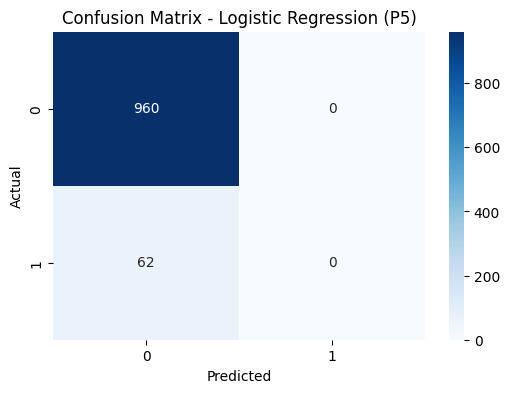

In [8]:
# Create Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix - Logistic Regression (P5)')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [10]:
# ====================== M3: REFINE THE MODEL ======================

# Method 1: Use class_weight='balanced' (Recommended & Simple)
model_refined = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',   # This handles class imbalance
    random_state=42
)

# Train the refined model
model_refined.fit(X_train, y_train)

print("Refined Logistic Regression model trained successfully!")

Refined Logistic Regression model trained successfully!


In [11]:
# Predict with refined model
y_pred_refined = model_refined.predict(X_test)

# Accuracy
accuracy_refined = accuracy_score(y_test, y_pred_refined)
print(f"Refined Model Accuracy: {accuracy_refined:.4f}")

# Classification Report
print("\nRefined Model Classification Report:")
print(classification_report(y_test, y_pred_refined))

Refined Model Accuracy: 0.7495

Refined Model Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.75      0.85       960
           1       0.16      0.76      0.27        62

    accuracy                           0.75      1022
   macro avg       0.57      0.75      0.56      1022
weighted avg       0.93      0.75      0.81      1022



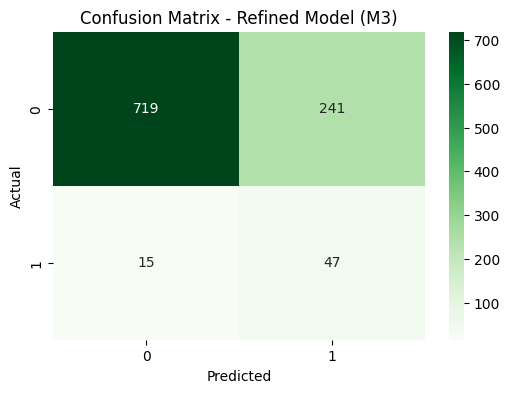

In [12]:
# Confusion Matrix - Refined Model
cm_refined = confusion_matrix(y_test, y_pred_refined)

plt.figure(figsize=(6,4))
sns.heatmap(cm_refined, annot=True, fmt='d', cmap='Greens')
plt.title('Confusion Matrix - Refined Model (M3)')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [13]:
# Create comparison table
comparison = pd.DataFrame({
    'Metric': ['Accuracy', 'Recall (Stroke)', 'Precision (Stroke)', 'F1-Score (Stroke)'],
    'Initial Model (P5)': [0.9393, 0.00, 0.00, 0.00],
    'Refined Model (M3)': [
        accuracy_refined,
        classification_report(y_test, y_pred_refined, output_dict=True)['1']['recall'],
        classification_report(y_test, y_pred_refined, output_dict=True)['1']['precision'],
        classification_report(y_test, y_pred_refined, output_dict=True)['1']['f1-score']
    ]
})

print("=== Before vs After Comparison ===")
print(comparison)

=== Before vs After Comparison ===
               Metric  Initial Model (P5)  Refined Model (M3)
0            Accuracy              0.9393            0.749511
1     Recall (Stroke)              0.0000            0.758065
2  Precision (Stroke)              0.0000            0.163194
3   F1-Score (Stroke)              0.0000            0.268571


In [14]:
# Install imbalanced-learn (run this only once)
!pip install imbalanced-learn

from imblearn.over_sampling import SMOTE

# Apply SMOTE
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print("After SMOTE - Class distribution:")
print(pd.Series(y_train_smote).value_counts())

# Train model with SMOTE data
model_smote = LogisticRegression(max_iter=1000, random_state=42)
model_smote.fit(X_train_smote, y_train_smote)

y_pred_smote = model_smote.predict(X_test)
print("\nSMOTE Model Accuracy:", accuracy_score(y_test, y_pred_smote))
print(classification_report(y_test, y_pred_smote))

After SMOTE - Class distribution:
stroke
0    3901
1    3901
Name: count, dtype: int64

SMOTE Model Accuracy: 0.7847358121330724
              precision    recall  f1-score   support

           0       0.97      0.80      0.87       960
           1       0.16      0.61      0.26        62

    accuracy                           0.78      1022
   macro avg       0.57      0.70      0.57      1022
weighted avg       0.92      0.78      0.84      1022

